## Firm Size and Job-Based Social Protections

#### Jobs, Workers, and Development (Fall 2026) | Prof. Ani Rudra Silwal | Georgetown University | Emilia Antunez:

**Research question:** Does the size of a firm affect how many social protections workers receive?

**Purpose:** Download CPS ASEC 1996–2026 from IPUMS, clean the variables, run the data sanity checks, build unweighted and weighted summary statistics tables, and save both.

**Output:** `firmsize_clean_data.csv` (private wage and salary workers aged 16–64 who worked last year) and `table1_weighted.csv` (summary statistics table).

| Variable | Description |
|---|---|
| year | Survey year (1996–2026) |
| age | Age in years |
| asecwt | ASEC person weight (use for health insurance, pension and all covariates) |
| earnwt | Earner study weight (use for union and hourly pay) |
| **Outcomes** | |
| emp_hins | 1 = had employer-sponsored health insurance last year, 0 = not (from GRPOWNLY, confirmed with VERIFY) |
| pension | 1 = included in a pension/retirement plan at work, 0 = not (from PENSION) |
| union | 1 = union member or covered by a union contract, 0 = not (from UNION; earner study only) |
| **Explanatory** | |
| firmsize4 | Firm size: 1 = under 10 workers, 2 = 10–99, 3 = 100–499, 4 = 500+ (from FIRMSIZE) |
| micro, small, medium, large | One 0/1 dummy per firmsize4 group |
| industry | Industry of longest job last year, 12 broad groups (from IND90LY, 1990 Census codes, consistent across years) |
| **Covariates** | |
| male | 1 = male, 0 = female |
| race5 | 1 = White, 2 = Black, 3 = Asian, 4 = Hispanic (any race), 5 = Other (1–3 and 5 are non-Hispanic) |
| white, black, asian, hispanic, other_race | One 0/1 dummy per race5 group |
| educ4 | 1 = less than high school, 2 = high school, 3 = some college/associate, 4 = bachelor's or more |
| lths, hs, somecol, baplus | One 0/1 dummy per educ4 group |
| married | 1 = married (spouse present or absent), 0 = not married |
| has_child | 1 = has own child(ren) in the household, 0 = none |
| *_label | The same variables in words, for tabulating |

**Timing note:** FIRMSIZE, PENSION, GRPOWNLY, IND90LY and CLASSWLY describe the **longest job last calendar year**. UNION describes the **current job in March**.

**Data sanity checklist**: look for `# Check N` in the code below.

1. Did you download every variable you need, for the years you intended? Tabulate `YEAR` to confirm.
2. Does each person appear only once? Check for duplicates on `YEAR` + `SERIAL` + `PERNUM`.
3. Did you convert IPUMS NIU and missing codes to missing before computing anything?
4. Did you tabulate every categorical variable, and does each distribution make sense?
5. Did you cross-tabulate every recoded variable against the original it came from, and does every change make sense?
6. Do the mean, min and max of each continuous variable make sense?
7. Does your sample size make sense? Report N after each filter and how much it shrank from the original.
8. Is a large share (~half) of any variable missing? If so, why?
9. Do you have an unweighted summary statistics table?
10. Do you have a weighted summary statistics table using the right weight? Where do the weighted and unweighted numbers differ most?

---
## 0. Setup

In [ ]:
!pip install ipumspy                                   # tool for downloading IPUMS data

import pandas as pd                                  # tables of data
import numpy as np                                   # math, and np.nan for missing values
from ipumspy import IpumsApiClient, MicrodataExtract, readers   # talk to the IPUMS API
from pathlib import Path                             # find files in the folder

---
## 1. Download data from IPUMS through the API

CPS ASEC samples 1996–2026.

a) HINSEMP (employer-sponsored health insurance) is available from 1996 to 2026. The series has measurement breaks in 2001 (verification question, adjusted using VERIFY), 2014 (questionnaire redesign), and 2019 (universe change and new imputation/weighting). I recode 2019+ non-universe cases to 0, include year fixed effects, and test whether the firm-size gap shifts at 2014 and 2019.

b) FIRMSIZE has the same categories from 1992 to 2026 (categories change in 2011). This extract will take several minutes to process.

In [ ]:
IPUMS_API_KEY = "59cba10d8a5da536fc06b59df82dd72ca3af44bea987d03a2217d9d9"
ipums = IpumsApiClient(IPUMS_API_KEY)                # connect to IPUMS

samples = [f"cps{year}_03s" for year in range(1996, 2027)]   # ASEC samples, 1996-2026 (range stops before 2027)

# Keep only the samples IPUMS has released (the newest ASEC year can come out late)
available = ipums.get_all_sample_info("cps")         # {sample id: description}
missing = [s for s in samples if s not in available]
samples = [s for s in samples if s in available]
print(f"Requesting {len(samples)} ASEC samples: {samples[0]} to {samples[-1]}")
if missing:
    print("Not yet available on IPUMS, skipped:", missing)

extract = MicrodataExtract(                          # describe the data we want
    collection="cps",                                # Current Population Survey
    samples=samples,                                 # which years
    description="Firm size and social protections, ASEC 1996-2026",
    variables=[
        "YEAR", "AGE", "SEX", "RACE", "HISPAN", "EDUC", # demographics
        "MARST", "NCHILD",                           # family structure
        "WORKLY", "CLASSWLY", "IND90LY", "FIRMSIZE",  # job last year: worked?, class of worker, industry, firm size
        "GRPOWNLY", "VERIFY", "PENSION",              # outcomes asked about last year's job (VERIFY: 2001+ insurance check)
        "UNION",                                      # outcomes asked about the current job (earner study)
        "ASECWT", "EARNWT",                          # weights
    ],                                               # which variables
)

ipums.submit_extract(extract)                        # send the request
print("Extract submitted, waiting for processing...")
ipums.wait_for_extract(extract)                      # wait until IPUMS is done (several minutes)
ipums.download_extract(extract, download_dir=Path("."))   # download the files
print("Download complete!")

ddi_file = list(Path(".").glob("*.xml"))[0]          # the codebook file
dat_file = list(Path(".").glob("*.dat.gz"))[0]       # the data file
ddi = readers.read_ipums_ddi(ddi_file)               # read the codebook
df = readers.read_microdata(ddi, dat_file)           # read the data into df

print(f"Rows: {df.shape[0]:,}")                      # number of people
print(f"Columns: {df.shape[1]}")                     # number of variables
df.head()                                            # first five rows

Extract submitted, waiting for processing...
Download complete!


/usr/local/lib/python3.13/dist-packages/ipumspy/readers.py:70: CitationWarning: Use of data from IPUMS is subject to conditions including that users should cite the data appropriately.
See the `ipums_conditions` attribute of this codebook for terms of use.
See the `ipums_citation` attribute of this codebook for the appropriate citation.
  warnings.warn(


Rows: 5,421,048
Columns: 27


,YEAR,SERIAL,MONTH,CPSID,ASECFLAG,HFLAG,ASECWTH,PERNUM,CPSIDP,CPSIDV,...,EDUC,EARNWT,IND90LY,CLASSWLY,WORKLY,PENSION,FIRMSIZE,VERIFY,GRPOWNLY,UNION
0,1996,1,3,19961300000100,1,<NA>,858.15,1,19961300000101,199613000001011,...,73,4150.21,510,22,2,1,1,<NA>,1,1
1,1996,1,3,19961300000100,1,<NA>,858.15,2,19961300000102,199613000001021,...,1,3661.55,0,0,0,0,0,<NA>,0,0
2,1996,1,3,19961300000100,1,<NA>,858.15,3,19961300000103,199613000001031,...,1,3165.86,0,0,0,0,0,<NA>,0,0
3,1996,2,3,19951202360600,1,<NA>,858.15,1,19951202360601,199512023606011,...,73,3416.16,0,0,1,0,0,<NA>,1,0
4,1996,5,3,19951202349600,1,<NA>,1003.13,1,19951202349601,199512023496011,...,73,4161.57,421,22,2,3,7,<NA>,1,1


**Look up the codes before recoding.** The codebook (DDI) that came with the data lists every code and its label. Print them for the variables we will recode, so every `.map()` below can be checked against the real codes.

In [ ]:
for var in ["FIRMSIZE", "GRPOWNLY", "VERIFY", "PENSION", "UNION", "WORKLY", "CLASSWLY", "MARST"]:
    print(var)                                       # variable name
    print(ddi.get_variable_info(var).codes)          # {label: code} from the IPUMS codebook
    print()

FIRMSIZE
{'NIU': 0, 'Under 10': 1, '10 to 24': 2, 'Under 25': 3, '10 to 49': 4, '25 to 99': 5, '50 to 99': 6, '100 to 499': 7, '500 to 999': 8, '1000+': 9}

GRPOWNLY
{'NIU': 0, 'No': 1, 'Yes': 2}

VERIFY
{'NIU': 0, 'No, uninsured': 1, 'Yes, insured': 2}

PENSION
{'NIU': 0, 'No pension plan at work': 1, 'Pension plan at work, but not included': 2, 'Included in pension plan at work': 3}

UNION
{'NIU': 0, 'No union coverage': 1, 'Member of labor union': 2, 'Covered by union but not a member': 3}

WORKLY
{'NIU': 0, 'No': 1, 'Yes': 2}

CLASSWLY
{'NIU': 0, 'Self-employed': 10, 'Self-employed, not incorporated': 13, 'Self-employed, incorporated': 14, 'Works for wages or salary': 20, 'Wage/salary, private': 22, 'Wage/salary, government': 24, 'Federal government employee': 25, 'State government employee': 27, 'Local government employee': 28, 'Unpaid family worker': 29, 'Missing/Unknown': 99}

MARST
{'Married, spouse present': 1, 'Married, spouse absent': 2, 'Separated': 3, 'Divorced': 4, 'Widow

---
## 2. First look at the data

In [ ]:
df1 = df.copy()                                      # a separate copy, so changes to df1 don't change df

In [ ]:
df1.shape                                            # (rows, columns)

(5421048, 27)

In [ ]:
print(df1.columns)                                   # variable names
print(df1.dtypes)                                    # variable types

Index(['YEAR', 'SERIAL', 'MONTH', 'CPSID', 'ASECFLAG', 'HFLAG', 'ASECWTH',
       'PERNUM', 'CPSIDP', 'CPSIDV', 'ASECWT', 'AGE', 'SEX', 'RACE', 'MARST',
       'NCHILD', 'HISPAN', 'EDUC', 'EARNWT', 'IND90LY', 'CLASSWLY', 'WORKLY',
       'PENSION', 'FIRMSIZE', 'VERIFY', 'GRPOWNLY', 'UNION'],
      dtype='object')
YEAR          Int64
SERIAL        Int64
MONTH         Int64
CPSID         Int64
ASECFLAG      Int64
HFLAG         Int64
ASECWTH     float64
PERNUM        Int64
CPSIDP        Int64
CPSIDV        Int64
ASECWT      float64
AGE           Int64
SEX           Int64
RACE          Int64
MARST         Int64
NCHILD        Int64
HISPAN        Int64
EDUC          Int64
EARNWT      float64
IND90LY       Int64
CLASSWLY      Int64
WORKLY        Int64
PENSION       Int64
FIRMSIZE      Int64
VERIFY        Int64
GRPOWNLY      Int64
UNION         Int64
dtype: object


In [ ]:
print(df1.describe())                                # summary stats for every variable

              YEAR        SERIAL      MONTH                  CPSID   ASECFLAG  \
count    5421048.0     5421048.0  5421048.0              5421048.0  5421048.0   
mean   2010.407676  47034.374349        3.0  20099286351529.929688        1.0   
std       8.058992  27535.440345        0.0     80790516430.715134        0.0   
min         1996.0           1.0        3.0       19951200000100.0        1.0   
25%         2004.0       23232.0        3.0       20031206886900.0        1.0   
50%         2010.0       46279.0        3.0       20100106278700.0        1.0   
75%         2017.0       70391.0        3.0       20161308863800.0        1.0   
max         2025.0       99986.0        3.0       20251308893200.0        1.0   

          HFLAG       ASECWTH     PERNUM                 CPSIDP  \
count  199556.0  5.421048e+06  5421048.0              5421048.0   
mean   0.301374  1.698309e+03    2.26347  20099368221312.472656   
std    0.458856  1.172571e+03   1.383409     80807586806.590454   
mi

In [ ]:
# Check 1: are all the years you asked for here?
print(df1["YEAR"].value_counts().sort_index())       # people per year, in year order

YEAR
1996    130476
1997    131854
1998    131617
1999    132324
2000    133710
2001    218269
2002    217219
2003    216424
2004    213241
2005    210648
2006    208562
2007    206639
2008    206404
2009    207921
2010    209802
2011    204983
2012    201398
2013    202634
2014    199556
2015    199024
2016    185487
2017    185914
2018    180084
2019    180101
2020    157959
2021    163543
2022    152732
2023    146133
2024    144265
2025    142125
Name: count, dtype: Int64


In [ ]:
# Check 2: does anyone appear twice?
print(df1.duplicated(subset=["YEAR", "SERIAL", "PERNUM"]).sum())   # number of duplicate people (should be 0)

0


In [ ]:
# Check 7: starting sample size
print(df1.shape[0])                                  # number of rows before any filter

5421048


---
## 3. Clean continuous variables

Replace NIU/missing codes with NaN. The codes differ by variable — check each one on the IPUMS website.

In [ ]:
# Check 3: does AGE have a code that needs to be recoded?
df1["AGE"].describe()                                # AGE is top-coded (around 85), but has no NIU code

,AGE
count,5421048.0
mean,35.451047
std,22.384837
min,0.0
25%,16.0
50%,35.0
75%,52.0
max,90.0


In [ ]:
# NCHILD: number of own children in the household (0-9, no NIU code)
print(df1["NCHILD"].describe())                      # max should be 9 at most

count    5421048.0
mean      0.620197
std       1.056679
min            0.0
25%            0.0
50%            0.0
75%            1.0
max            9.0
Name: NCHILD, dtype: Float64


In [ ]:
# Weights: ASECWT should be positive for everyone in the ASEC. EARNWT is 0 for people not in the earner study.
print(df1[["ASECWT", "EARNWT"]].describe().round(2)) # min, mean, max of each weight
print((df1["EARNWT"] > 0).mean().round(2))           # share of people in the earner study (Only wage and salary workers in households in their 4th or 8th interview month are asked the earnings questions. Everyone else, including non-workers, the self-employed, and workers in other months, gets an EARNWT of 0)

           ASECWT      EARNWT
count  5421048.00  5421048.00
mean      1735.80     1389.34
std       1224.69     3975.43
min          0.00        0.00
25%        866.04        0.00
50%       1560.17        0.00
75%       2302.55        0.00
max      44423.83    85013.19
0.15


In [ ]:
# Check 6: do the mean, min and max make sense?
df1[["AGE", "NCHILD", "ASECWT", "EARNWT"]].describe().round(2)

,AGE,NCHILD,ASECWT,EARNWT
count,5421048.0,5421048.0,5421048.00,5421048.00
mean,35.45,0.62,1735.80,1389.34
std,22.38,1.06,1224.69,3975.43
min,0.0,0.0,0.00,0.00
25%,16.0,0.0,866.04,0.00
50%,35.0,0.0,1560.17,0.00
75%,52.0,1.0,2302.55,0.00
max,90.0,9.0,44423.83,85013.19


---
## 4. Clean categorical and dummy variables

In [ ]:
# Check 4: does each distribution make sense?
for var in ["SEX", "RACE", "HISPAN", "EDUC", "MARST", "WORKLY", "CLASSWLY",
            "FIRMSIZE", "GRPOWNLY", "VERIFY", "PENSION", "UNION"]:   # every categorical variable
    counts = df1[var].value_counts().sort_index()                                # N for each code
    pct = (df1[var].value_counts(normalize=True).sort_index() * 100).round(1)    # % for each code
    print(var)
    print(pd.DataFrame({"N": counts, "%": pct}))                                 # N and % side by side
    print()

SEX
           N     %
SEX               
1    2631559  48.5
2    2789489  51.5

RACE
            N     %
RACE               
100   4299453  79.3
200    625290  11.5
300     80012   1.5
650     43315   0.8
651    235580   4.3
652     21601   0.4
801     29918   0.6
802     39001   0.7
803     20217   0.4
804      5145   0.1
805      4377   0.1
806      1509   0.0
807       463   0.0
808       370   0.0
809      4126   0.1
810      3325   0.1
811       625   0.0
812       579   0.0
813      4347   0.1
814       172   0.0
815        90   0.0
816       131   0.0
817        97   0.0
818        54   0.0
819        29   0.0
820       694   0.0
830       528   0.0

HISPAN
              N     %
HISPAN               
0       4459809  82.3
100      497282   9.2
102       44484   0.8
104        2437   0.0
108       54386   1.0
200       86735   1.6
300       33484   0.6
400       12574   0.2
500       13845   0.3
600       61900   1.1
610       91688   1.7
611       24969   0.5
612       26213   

### 4a. Outcome variables

In [ ]:
# Employer health insurance (GRPOWNLY): policyholder for employment-based insurance last year.
# Codes: 0 = NIU, 1 = no, 2 = yes.
df1["emp_hins"] = df1["GRPOWNLY"].map({1: 0, 2: 1})

# 2019+: only people with employer coverage are in the universe, so NIU means no coverage -> 0
df1.loc[(df1["YEAR"] >= 2019) & (df1["GRPOWNLY"] == 0), "emp_hins"] = 0

# Check 5: new vs. original
print(pd.crosstab(df1["GRPOWNLY"], df1["emp_hins"], dropna=False))
print(pd.crosstab(df1["YEAR"] >= 2019, [df1["GRPOWNLY"], df1["emp_hins"]], dropna=False))

emp_hins      0.0      1.0      NaN
GRPOWNLY                           
0          490009        0  1034232
1         2337750        0        0
2               0  1559057        0
GRPOWNLY       0                     1           2             
emp_hins     0.0 1.0      NaN      0.0 1.0 NaN 0.0      1.0 NaN
YEAR                                                           
False          0   0  1034232  2043237   0   0   0  1256721   0
True      490009   0        0   294513   0   0   0   302336   0


In [ ]:
# Comparability across 2001: starting in 2001 the CPS asked a "verification" question (VERIFY) that
# picks up extra people with coverage. Earlier years did not ask it. IPUMS recommends, for a time
# series across 2001, treating people coded "Yes" (2) in VERIFY as not covered, so every year is
# measured the same way. VERIFY exists 2001-2018, but has no "Yes" answers from 2014 on,
# so in practice this only changes 2001-2013.
print(pd.crosstab(df1["YEAR"], df1["VERIFY"]))       # "Yes" (2) should appear only in 2001-2013

verify_fix = (df1["VERIFY"] == 2) & (df1["GRPOWNLY"] == 2)   # said yes to GRPOWNLY only via verification
df1.loc[verify_fix, "emp_hins"] = 0                          # -> not covered

# Check 5: who changed?
print(verify_fix.groupby(df1["YEAR"]).sum())                 # should be >0 only in 2001-2013, total 10,253
pd.crosstab([df1["GRPOWNLY"], df1["VERIFY"]], df1["emp_hins"], dropna=False)

VERIFY       0      1     2
YEAR                       
2001    184773  30727  2769
2002    183394  31210  2615
2003    181077  32761  2586
2004    177556  33159  2526
2005    176879  30894  2875
2006    174078  31716  2768
2007    171501  32209  2929
2008    172953  31387  2064
2009    174126  31746  2049
2010    172831  35002  1969
2011    169347  33735  1901
2012    167699  31941  1758
2013    169121  31550  1963
2014    172452  27104     0
2015    177341  21683     0
2016    167864  17623     0
2017    168676  17238     0
2018    163002  17082     0
YEAR
1996       0
1997       0
1998       0
1999       0
2000       0
2001     965
2002     999
2003     853
2004     940
2005    1015
2006     944
2007     943
2008     726
2009     677
2010     618
2011     525
2012     510
2013     538
2014       0
2015       0
2016       0
2017       0
2018       0
2019       0
2020       0
2021       0
2022       0
2023       0
2024       0
2025       0
dtype: Int64


emp_hins             0.0      1.0     NaN
GRPOWNLY VERIFY                          
0        0             0        0  767603
         1             0        0  105326
         2             0        0    8162
         <NA>     490009        0  153141
1        0       1317592        0       0
         1        413441        0       0
         2         12357        0       0
         <NA>     594360        0       0
2        0             0  1039475       0
         1             0        0       0
         2         10253        0       0
         <NA>          0   509329       0

In [ ]:
# Pension (PENSION): 1 = no plan at work, 2 = plan at work but not included, 3 = included. 0 (NIU) -> missing.
df1["pension"] = df1["PENSION"].map({1: 0, 2: 0, 3: 1})

# Check 5
pd.crosstab(df1["PENSION"], df1["pension"], dropna=False)    # new vs original

pension,0.0,1.0,NaN
PENSION,,,
0,0,0,2658187
1,1412557,0,0
2,282014,0,0
3,0,1068290,0


In [ ]:
# Union (UNION): 1 = no union coverage, 2 = member, 3 = covered but not a member. 0 (NIU) -> missing.
df1["union"] = df1["UNION"].map({1: 0, 2: 1, 3: 1})

# Check 5
pd.crosstab(df1["UNION"], df1["union"], dropna=False)        # new vs original

union,0.0,1.0,NaN
UNION,,,
0,0,0,5000978
1,362830,0,0
2,0,51510,0
3,0,5730,0


### 4b. Explanatory variables

**Firm size.** I group the categories into four: micro (under 10), small (10-99), medium (100–499) and large (500+). This grouping also works for every other year of the CPS (the 2011–2018 categories 10–49 and 50–99 both fall in "10-99"), so it stays comparable if I add years later.

In [ ]:
# Firm size, 4 groups. Codes differ by period:
#   1992-2010 and 2019+: under 10 / 10-24 / 25-99 / 100-499 / 500-999 / 1000+
#   2011-2018:           under 10 / 10-49 / 50-99 / 100-499 / 500-999 / 1000+
# CHECK each code below against the codebook printout.
firm_map = {
    1: 1,                 # under 10                          -> 1 "under 10"
    2: 2,                 # 10-24      (1992-2010, 2019+)     -> 2 "10-99"
    4: 2,                 # 10-49      (2011-2018)            -> 2 "10-99"
    5: 2,                 # 25-99      (1992-2010, 2019+)     -> 2 "10-99"
    6: 2,                 # 50-99      (2011-2018)            -> 2 "10-99"
    7: 3,                 # 100-499                           -> 3 "100-499"
    8: 4, 9: 4,           # 500-999, 1000+                    -> 4 "500+"
}                         # 0 (NIU) -> missing; 3 ("under 25", 1988-91 only) -> missing
df1["firmsize4"] = df1["FIRMSIZE"].map(firm_map)

firm_labels = {1: "under 10", 2: "10-99", 3: "100-499", 4: "500+"}
df1["firmsize4_label"] = df1["firmsize4"].map(firm_labels)

# Check 5: new vs. original
print(pd.crosstab(df1["FIRMSIZE"], df1["firmsize4"], dropna=False))
# Each original code should land in exactly one new group, and codes should switch by period:
print(pd.crosstab(df1["YEAR"], df1["FIRMSIZE"]))

firmsize4     1.0     2.0     3.0      4.0      NaN
FIRMSIZE                                           
0               0       0       0        0  2658187
1          562817       0       0        0        0
2               0  218912       0        0        0
4               0  115757       0        0        0
5               0  222505       0        0        0
6               0   54865       0        0        0
7               0       0  351402        0        0
8               0       0       0   144772        0
9               0       0       0  1091831        0
FIRMSIZE       0      1      2      4      5     6      7     8      9
YEAR                                                                  
1996       62340  14826   6531      0   8722     0   9222  3821  25014
1997       62419  14851   6515      0   8916     0   9481  3835  25837
1998       61965  14668   6417      0   8928     0   9203  3854  26582
1999       62038  14704   6584      0   8979     0   9711  3886  26422
20

In [ ]:
df1["micro"] = np.where(df1["firmsize4"].isna(), np.nan, (df1["firmsize4"] == 1).astype(float))    # 1 if under 10
df1["small"] = np.where(df1["firmsize4"].isna(), np.nan, (df1["firmsize4"] == 2).astype(float))    # 1 if 10-99
df1["medium"] = np.where(df1["firmsize4"].isna(), np.nan, (df1["firmsize4"] == 3).astype(float))   # 1 if 100-499
df1["large"] = np.where(df1["firmsize4"].isna(), np.nan, (df1["firmsize4"] == 4).astype(float))    # 1 if 500+

In [ ]:
# Industry of longest job last year (IND90LY): 1990 Census industry codes, the same in every year.
# Group into 12 broad sectors. 0 = NIU -> missing. Military (940-960) and unknown (990+) -> missing.
def industry_group(code):
    if pd.isna(code) or code == 0:
        return np.nan
    if 10 <= code <= 32:     return 1                # Agriculture, forestry, fisheries
    if 40 <= code <= 50:     return 2                # Mining
    if code == 60:           return 3                # Construction
    if 100 <= code <= 392:   return 4                # Manufacturing
    if 400 <= code <= 472:   return 5                # Transportation, communications, utilities
    if 500 <= code <= 691:   return 6                # Wholesale and retail trade
    if 700 <= code <= 712:   return 7                # Finance, insurance, real estate
    if 721 <= code <= 760:   return 8                # Business and repair services
    if 761 <= code <= 791:   return 9                # Personal services
    if 800 <= code <= 810:   return 10               # Entertainment and recreation
    if 812 <= code <= 893:   return 11               # Professional services (incl. health, education)
    if 900 <= code <= 932:   return 12               # Public administration
    return np.nan                                    # military, unknown and anything else

df1["industry"] = df1["IND90LY"].apply(industry_group)

# Check 5: every IND90LY code should land in exactly one group (look at the ranges)
print(df1.groupby("industry")["IND90LY"].agg(["min", "max", "count"]))
print(df1.loc[df1["industry"].isna(), "IND90LY"].value_counts().head(10))   # which codes became missing?

          min  max   count
industry                  
1.0        10   32   80985
2.0        40   50   17601
3.0        60   60  197318
4.0       100  392  306542
5.0       400  472  184743
6.0       500  691  558511
7.0       700  712  171602
8.0       721  760  190327
9.0       761  791   92182
10.0      800  810   61893
11.0      812  893  751566
12.0      900  932  133262
IND90LY
0      2661246
952      13270
Name: count, dtype: Int64


### 4c. Covariates

In [ ]:
df1["male"] = df1["SEX"].map({1: 1, 2: 0})           # 1 = male, 2 = female

# Check 5
pd.crosstab(df1["SEX"], df1["male"], dropna=False)   # new vs original

male,0,1
SEX,,
1,0,2631559
2,2789489,0


In [ ]:
# Race and Hispanic origin: five groups. Everyone is in exactly one, so the shares add up to 100%.
# Hispanic first (any race), then non-Hispanic White, Black, Asian; everyone else is Other.
# HISPAN 901/902 (don't know / no response) are not counted as Hispanic.
# Asian: before 2003 the CPS had one "Asian or Pacific Islander" code (650); from 2003 "Asian only" is 651.
# I count both as Asian, so 1996-2002 "Asian" also includes Pacific Islanders (a small group).

def race_group(row):                                 # takes one row (needs both RACE and HISPAN)
    if 100 <= row["HISPAN"] <= 612:                  # any Hispanic origin code
        return 4                                     # Hispanic (any race)
    if row["RACE"] == 100:
        return 1                                     # White, non-Hispanic
    if row["RACE"] == 200:
        return 2                                     # Black, non-Hispanic
    if row["RACE"] in (650, 651):
        return 3                                     # Asian, non-Hispanic
    return 5                                         # Other: every other code, non-Hispanic

df1["race5"] = df1.apply(race_group, axis=1)         # axis=1: run the function on each row (takes a few seconds)

# Check 5
print(pd.crosstab(df1["HISPAN"], df1["race5"]))      # every Hispanic code (100-612) should land in 4
pd.crosstab(df1["RACE"], df1["race5"])               # each RACE code lands in its group or in 4

race5         1       2       3       4       5
HISPAN                                         
0       3412979  595169  272153       0  179508
100           0       0       0  497282       0
102           0       0       0   44484       0
104           0       0       0    2437       0
108           0       0       0   54386       0
200           0       0       0   86735       0
300           0       0       0   33484       0
400           0       0       0   12574       0
500           0       0       0   13845       0
600           0       0       0   61900       0
610           0       0       0   91688       0
611           0       0       0   24969       0
612           0       0       0   26213       0
901        4040     124      28       0      13
902        6414     382     213       0      28


race5,1,2,3,4,5
RACE,,,,,
100,3423433,0,0,876020,0
200,0,595675,0,29615,0
300,0,0,0,15227,64785
650,0,0,42171,1144,0
651,0,0,230223,5357,0
652,0,0,0,2971,18630
801,0,0,0,5943,23975
802,0,0,0,7210,31791
803,0,0,0,2107,18110


In [ ]:
df1["white"] = (df1["race5"] == 1).astype(int)       # 1 if White (non-Hispanic), else 0
df1["black"] = (df1["race5"] == 2).astype(int)       # 1 if Black (non-Hispanic), else 0
df1["asian"] = (df1["race5"] == 3).astype(int)       # 1 if Asian (non-Hispanic), else 0
df1["hispanic"] = (df1["race5"] == 4).astype(int)    # 1 if Hispanic (any race), else 0
df1["other_race"] = (df1["race5"] == 5).astype(int)  # 1 if Other (non-Hispanic), else 0

shares = df1[["white", "black", "asian", "hispanic", "other_race"]].mean()   # share in each group
print(shares.round(2))                               # share in each group
print(shares.sum().round(2))                         # shares must add up to 1

white         0.63
black         0.11
asian         0.05
hispanic      0.18
other_race    0.03
dtype: float64
1.0


In [ ]:
# Education (EDUC): four groups. 1 (NIU/blank) and 999 (missing) -> missing.
def educ_group(code):
    if code in (0, 1, 999):
        return np.nan                                # NIU or missing
    if code <= 72:
        return 1                                     # less than high school (no diploma)
    if code == 73:
        return 2                                     # high school diploma or GED
    if code <= 110:
        return 3                                     # some college or associate degree (81, 91, 92)
    return 4                                         # bachelor's or more (111, 123, 124, 125)

df1["educ4"] = df1["EDUC"].apply(educ_group)

# Check 5
pd.crosstab(df1["EDUC"], df1["educ4"], dropna=False) # new vs original

educ4,1.0,2.0,3.0,4.0,NaN
EDUC,,,,,
1,0,0,0,0,1257872
2,15517,0,0,0,0
10,34147,0,0,0,0
20,67325,0,0,0,0
30,131911,0,0,0,0
40,148706,0,0,0,0
50,168349,0,0,0,0
60,176031,0,0,0,0
71,68101,0,0,0,0


In [ ]:
df1["lths"] = np.where(df1["educ4"].isna(), np.nan, (df1["educ4"] == 1).astype(float))      # less than HS
df1["hs"] = np.where(df1["educ4"].isna(), np.nan, (df1["educ4"] == 2).astype(float))        # HS diploma
df1["somecol"] = np.where(df1["educ4"].isna(), np.nan, (df1["educ4"] == 3).astype(float))   # some college / associate
df1["baplus"] = np.where(df1["educ4"].isna(), np.nan, (df1["educ4"] == 4).astype(float))    # bachelor's or more

In [ ]:
# Family structure 1: marital status (MARST). 1-2 = married, 3-6 = separated/divorced/widowed/never married. 9 (NIU) -> missing.
df1["married"] = df1["MARST"].map({1: 1, 2: 1, 3: 0, 4: 0, 5: 0, 6: 0})

# Check 5
pd.crosstab(df1["MARST"], df1["married"], dropna=False)   # new vs original

married,0,1
MARST,,
1,0,2174216
2,0,55930
3,83415,0
4,391620,0
5,227892,0
6,2487975,0


In [ ]:
# Family structure 2: has own children in the household (NCHILD = number of own children)
df1["has_child"] = (df1["NCHILD"] > 0).astype(int)   # 1 if at least one child, else 0

# Check 5
pd.crosstab(df1["NCHILD"], df1["has_child"], dropna=False)   # 0 -> 0, 1-9 -> 1

has_child,0,1
NCHILD,,
0,3648085,0
1,0,736475
2,0,651301
3,0,269034
4,0,82542
5,0,22407
6,0,7122
7,0,2370
8,0,992


In [ ]:
# Labels: keep the number versions for means; use these to tabulate with words
df1["sex_label"] = df1["male"].map({1: "Male", 0: "Female"})
df1["race5_label"] = df1["race5"].map({1: "White", 2: "Black", 3: "Asian", 4: "Hispanic", 5: "Other"})
df1["educ4_label"] = df1["educ4"].map({1: "Less than HS", 2: "High school", 3: "Some college", 4: "BA or more"})
df1["married_label"] = df1["married"].map({1: "Married", 0: "Not married"})
df1["firmsize4_label"] = df1["firmsize4"].map({1: "Under 10", 2: "10-99", 3: "100-499", 4: "500+"})
df1["industry_label"] = df1["industry"].map({
    1: "Agriculture", 2: "Mining", 3: "Construction", 4: "Manufacturing", 5: "Transport/communications/utilities",
    6: "Wholesale/retail trade", 7: "Finance/insurance/real estate", 8: "Business and repair services",
    9: "Personal services", 10: "Entertainment/recreation", 11: "Professional services", 12: "Public administration"})
df1["emp_hins_label"] = df1["emp_hins"].map({1: "Employer health insurance", 0: "No employer health insurance"})
df1["pension_label"] = df1["pension"].map({1: "In pension plan", 0: "Not in pension plan"})
df1["union_label"] = df1["union"].map({1: "Union covered", 0: "Not union covered"})

for var in ["sex_label", "race5_label", "educ4_label", "married_label", "firmsize4_label",
            "industry_label", "emp_hins_label", "pension_label", "union_label"]:
    counts = df1[var].value_counts(dropna=False)                                   # N, with labels (NaN = not in universe)
    pct = (df1[var].value_counts(normalize=True, dropna=False) * 100).round(1)     # %, with labels
    print(pd.DataFrame({"N": counts, "%": pct}))                                   # N and % side by side
    print()

                 N     %
sex_label               
Female     2789489  51.5
Male       2631559  48.5

                   N     %
race5_label               
White        3423433  63.2
Hispanic      949997  17.5
Black         595675  11.0
Asian         272394   5.0
Other         179549   3.3

                    N     %
educ4_label                
NaN           1257872  23.2
High school   1186971  21.9
BA or more    1090562  20.1
Some college  1075556  19.8
Less than HS   810087  14.9

                     N     %
married_label               
Not married    3190902  58.9
Married        2230146  41.1

                       N     %
firmsize4_label               
NaN              2658187  49.0
500+             1236603  22.8
11-100            612039  11.3
Under 10          562817  10.4
100-499           351402   6.5

                                          N     %
industry_label                                   
NaN                                 2674516  49.3
Professional services      

---
## 5. Keep the analysis sample

Three filters, one at a time, reporting N after each:
1. Working-age adults, 16–64.
2. Worked at some point last year (WORKLY = 2), because firm size, pension and health insurance refer to last year's job.
3. Private-sector wage and salary workers in that job (CLASSLY 21–23: private for-profit and non-profit). This drops the self-employed (who have no employer) and government workers (where "firm size" means something different).

In [ ]:
# Check 7: how much did the sample shrink at each step?
n0 = df1.shape[0]
print(f"Start:                       {n0:,}")

df2 = df1[(df1["AGE"] >= 16) & (df1["AGE"] <= 64)]  # keep ages 16-64
print(f"Ages 16-64:                  {df2.shape[0]:,}  ({df2.shape[0] / n0:.0%} of start)")

df2 = df2[df2["WORKLY"] == 2]                        # worked last year
print(f"Worked last year:            {df2.shape[0]:,}  ({df2.shape[0] / n0:.0%} of start)")

df2 = df2[df2["CLASSWLY"].isin([21, 22, 23])]         # private wage/salary worker last year
print(f"Private wage/salary worker:  {df2.shape[0]:,}  ({df2.shape[0] / n0:.0%} of start)")

Start:                       5,421,048
Ages 16-64:                  3,418,115  (63% of start)
Worked last year:            2,615,838  (48% of start)
Private wage/salary worker:  1,975,763  (36% of start)


In [ ]:
# Check 5 on the filter: only private wage/salary codes should remain
print(df2["CLASSWLY"].value_counts().sort_index())
print(df2["firmsize4"].isna().mean().round(3))       # should be close to 0: everyone in the sample has a firm size

CLASSWLY
22    1975763
Name: count, dtype: Int64
0.0


In [ ]:
print([c for c in df2.columns if "lab" in c or "lbl" in c])

['firmsize4_label', 'sex_label', 'race5_label', 'educ4_label', 'married_label', 'industry_label', 'emp_hins_label', 'pension_label', 'union_label']


---
## 6. Clean up and summarize

In [ ]:
df2 = df2.rename(columns={"YEAR": "year", "AGE": "age", "ASECWT": "asecwt", "EARNWT": "earnwt"})   # lowercase names
print(df2.columns)                                   # check the new names

Index(['year', 'SERIAL', 'MONTH', 'CPSID', 'ASECFLAG', 'HFLAG', 'ASECWTH',
       'PERNUM', 'CPSIDP', 'CPSIDV', 'asecwt', 'age', 'SEX', 'RACE', 'MARST',
       'NCHILD', 'HISPAN', 'EDUC', 'earnwt', 'IND90LY', 'CLASSWLY', 'WORKLY',
       'PENSION', 'FIRMSIZE', 'VERIFY', 'GRPOWNLY', 'UNION', 'emp_hins',
       'pension', 'union', 'firmsize4', 'firmsize4_label', 'micro', 'small',
       'medium', 'large', 'industry', 'male', 'race5', 'white', 'black',
       'asian', 'hispanic', 'other_race', 'educ4', 'lths', 'hs', 'somecol',
       'baplus', 'married', 'has_child', 'sex_label', 'race5_label',
       'educ4_label', 'married_label', 'industry_label', 'emp_hins_label',
       'pension_label', 'union_label'],
      dtype='object')


In [ ]:
keep_vars = ["year", "age", "asecwt", "earnwt",
             "emp_hins", "pension", "union",                         # outcomes
             "firmsize4", "micro", "small", "medium", "large", "industry",              # explanatory
             "male", "race5", "white", "black", "asian", "hispanic", "other_race",
             "educ4", "lths", "hs", "somecol", "baplus", "married", "has_child",   # covariates
             "sex_label", "race5_label", "educ4_label", "married_label", "firmsize4_label",
             "industry_label", "emp_hins_label", "pension_label", "union_label"]
df2 = df2[keep_vars]                                 # drop everything else
print(df2.columns)                                   # check what's left

Index(['year', 'age', 'asecwt', 'earnwt', 'emp_hins', 'pension', 'union',
       'firmsize4', 'micro', 'small', 'medium', 'large', 'industry', 'male',
       'race5', 'white', 'black', 'asian', 'hispanic', 'other_race', 'educ4',
       'lths', 'hs', 'somecol', 'baplus', 'married', 'has_child', 'sex_label',
       'race5_label', 'educ4_label', 'married_label', 'firmsize4_label',
       'industry_label', 'emp_hins_label', 'pension_label', 'union_label'],
      dtype='object')


In [ ]:
# Check 9: unweighted summary statistics table
table_vars = ["emp_hins", "pension", "union",
              "micro", "small", "medium", "large",
              "age", "male", "white", "black", "asian", "hispanic", "other_race",
              "lths", "hs", "somecol", "baplus", "married", "has_child", "year"]   # variables in the table
table1 = df2[table_vars].describe().T[["count", "mean", "std", "min", "max"]].round(2)   # one row per variable
table1                                               # display the table

,count,mean,std,min,max
emp_hins,1975763.0,0.513291,0.499823,0.0,1.0
pension,1975763.0,0.367793,0.482205,0.0,1.0
union,323869.0,0.090095,0.286318,0.0,1.0
micro,1975763.0,0.147524,0.354628,0.0,1.0
small,1975763.0,0.268222,0.443034,0.0,1.0
medium,1975763.0,0.146378,0.353485,0.0,1.0
large,1975763.0,0.437875,0.496126,0.0,1.0
age,1975763.0,38.327751,12.58639,16.0,64.0
male,1975763.0,0.521162,0.499552,0.0,1.0
white,1975763.0,0.641042,0.479695,0.0,1.0


In [ ]:
# Check 8: share NOT missing for each variable. Is a large share (~half) missing? Why?
# Expect union and hourly to be missing for roughly 3/4 of the sample: only the earner study
# (outgoing rotation groups) is asked these questions. That is the universe, not an error.
print((table1["count"] / df2.shape[0]).round(2))     # count / total rows

emp_hins           1.0
pension            1.0
union         0.163921
micro              1.0
small              1.0
medium             1.0
large              1.0
age                1.0
male               1.0
white              1.0
black              1.0
asian              1.0
hispanic           1.0
other_race         1.0
lths               1.0
hs                 1.0
somecol            1.0
baplus             1.0
married            1.0
has_child          1.0
year               1.0
Name: count, dtype: object


In [ ]:
# Check 10: weighted summary statistics table.
# ASECWT for everything except union, which uses EARNWT (the earner study weight).
earner_vars = ["union"]

def wstats(data, var):                               # all the statistics for one variable
    wvar = "earnwt" if var in earner_vars else "asecwt"   # pick the right weight
    d = data.dropna(subset=[var])                    # drop rows missing that variable
    d = d[d[wvar] > 0]                               # keep people with a positive weight
    x = d[var]                                       # the values
    w = d[wvar]                                      # the weights
    m = np.average(x, weights=w)                     # weighted mean
    sd = np.sqrt(np.average((x - m) ** 2, weights=w))    # weighted SD
    return {"count": len(d), "mean": m, "std": sd, "min": x.min(), "max": x.max(), "weight": wvar.upper()}

headings = {"emp_hins": "Outcomes:", "micro": "Firm size:", "age": "Covariates:",
            "white": "Race and Hispanic origin:", "lths": "Education:"}   # heading rows

rows = {}                                            # empty dictionary for the rows
for var in table_vars:                               # loop over the table variables
    if var in headings:                              # put a heading row before each block
        rows[headings[var]] = {}
    rows[var] = wstats(df2, var)                     # statistics for each variable

table1w = pd.DataFrame(rows).T                       # dictionary -> table, one row per variable

labels = {"emp_hins": "Employer-sponsored health insurance", "pension": "Included in pension plan",
          "union": "Union member or covered",
          "micro": "Under 10 workers", "small": "10-99 workers", "medium": "100-499 workers", "large": "500+ workers",
          "age": "Age (years)", "male": "Male",
          "white": "White, non-Hispanic", "black": "Black, non-Hispanic", "asian": "Asian, non-Hispanic",
          "hispanic": "Hispanic (any race)", "other_race": "Other, non-Hispanic",
          "lths": "Less than high school", "hs": "High school diploma", "somecol": "Some college/associate",
          "baplus": "Bachelor's or more", "married": "Married", "has_child": "Has own children",
          "year": "Survey year"}                     # variable names -> labels
columns = {"count": "N", "mean": "Mean", "std": "SD", "min": "Min", "max": "Max", "weight": "Weight"}
table1w = table1w.rename(index=labels, columns=columns)   # apply both
for c in ["N", "Mean", "SD", "Min", "Max"]:
    table1w[c] = pd.to_numeric(table1w[c])           # numbers, so they can be formatted

# Compare with Table 1 above: where do the unweighted and weighted means differ most?
(table1w.style
 .format({"N": "{:,.0f}", "Mean": "{:,.2f}", "SD": "{:,.2f}",
          "Min": "{:,.0f}", "Max": "{:,.0f}"}, na_rep="")                  # blank heading rows
 .format("{:.2f}", subset=(["Survey year"], ["Mean", "SD"]))              # no comma in a year
 .format("{:.0f}", subset=(["Survey year"], ["Min", "Max"])))

,N,Mean,SD,Min,Max,Weight
Outcomes:,,,,,,
Employer-sponsored health insurance,"1,975,747",0.52,0.50,0,1,ASECWT
Included in pension plan,"1,975,747",0.36,0.48,0,1,ASECWT
Union member or covered,"323,851",0.09,0.29,0,1,EARNWT
Firm size:,,,,,,
Under 10 workers,"1,975,747",0.14,0.35,0,1,ASECWT
11-100 workers,"1,975,747",0.26,0.44,0,1,ASECWT
100-499 workers,"1,975,747",0.14,0.35,0,1,ASECWT
500+ workers,"1,975,747",0.45,0.50,0,1,ASECWT
Covariates:,,,,,,


In [ ]:
# Check 10.B: WITHOUT MAX AND MIN.
# ASECWT for everything except union, which uses EARNWT (the earner study weight).
earner_vars = ["union"]

def wstats(data, var):                               # all the statistics for one variable
    wvar = "earnwt" if var in earner_vars else "asecwt"   # pick the right weight
    d = data.dropna(subset=[var])                    # drop rows missing that variable
    d = d[d[wvar] > 0]                               # keep people with a positive weight
    x = d[var]                                       # the values
    w = d[wvar]                                      # the weights
    m = np.average(x, weights=w)                     # weighted mean
    sd = np.sqrt(np.average((x - m) ** 2, weights=w))    # weighted SD
    return {"count": len(d), "mean": m, "std": sd, "weight": wvar.upper()}

headings = {"emp_hins": "Outcomes:", "micro": "Firm size:", "age": "Covariates:",
            "white": "Race and Hispanic origin:", "lths": "Education:"}   # heading rows

rows = {}                                            # empty dictionary for the rows
for var in table_vars:                               # loop over the table variables
    if var in headings:                              # put a heading row before each block
        rows[headings[var]] = {}
    rows[var] = wstats(df2, var)                     # statistics for each variable

table1w = pd.DataFrame(rows).T                       # dictionary -> table, one row per variable

labels = {"emp_hins": "Employer-sponsored health insurance", "pension": "Included in pension plan",
          "union": "Union member or covered",
          "micro": "Under 10 workers", "small": "10-99 workers", "medium": "100-499 workers", "large": "500+ workers",
          "age": "Age (years)", "male": "Male",
          "white": "White, non-Hispanic", "black": "Black, non-Hispanic", "asian": "Asian, non-Hispanic",
          "hispanic": "Hispanic (any race)", "other_race": "Other, non-Hispanic",
          "lths": "Less than high school", "hs": "High school diploma", "somecol": "Some college/associate",
          "baplus": "Bachelor's or more", "married": "Married", "has_child": "Has own children",
          "year": "Survey year"}                     # variable names -> labels
columns = {"count": "N", "mean": "Mean", "std": "SD", "weight": "Weight"}
table1w = table1w.rename(index=labels, columns=columns)   # apply both
for c in ["N", "Mean", "SD"]:
    table1w[c] = pd.to_numeric(table1w[c])           # numbers, so they can be formatted

# Compare with Table 1 above: where do the unweighted and weighted means differ most?
(table1w.style
 .format({"N": "{:,.0f}", "Mean": "{:,.2f}", "SD": "{:,.2f}",
          "Min": "{:,.0f}", "Max": "{:,.0f}"}, na_rep="")                  # blank heading rows
 .format("{:.2f}", subset=(["Survey year"], ["Mean", "SD"]))              # no comma in a year
 )


,N,Mean,SD,Weight
Outcomes:,,,,
Employer-sponsored health insurance,"1,975,747",0.52,0.50,ASECWT
Included in pension plan,"1,975,747",0.36,0.48,ASECWT
Union member or covered,"323,851",0.09,0.29,EARNWT
Firm size:,,,,
Under 10 workers,"1,975,747",0.14,0.35,ASECWT
11-100 workers,"1,975,747",0.26,0.44,ASECWT
100-499 workers,"1,975,747",0.14,0.35,ASECWT
500+ workers,"1,975,747",0.45,0.50,ASECWT
Covariates:,,,,


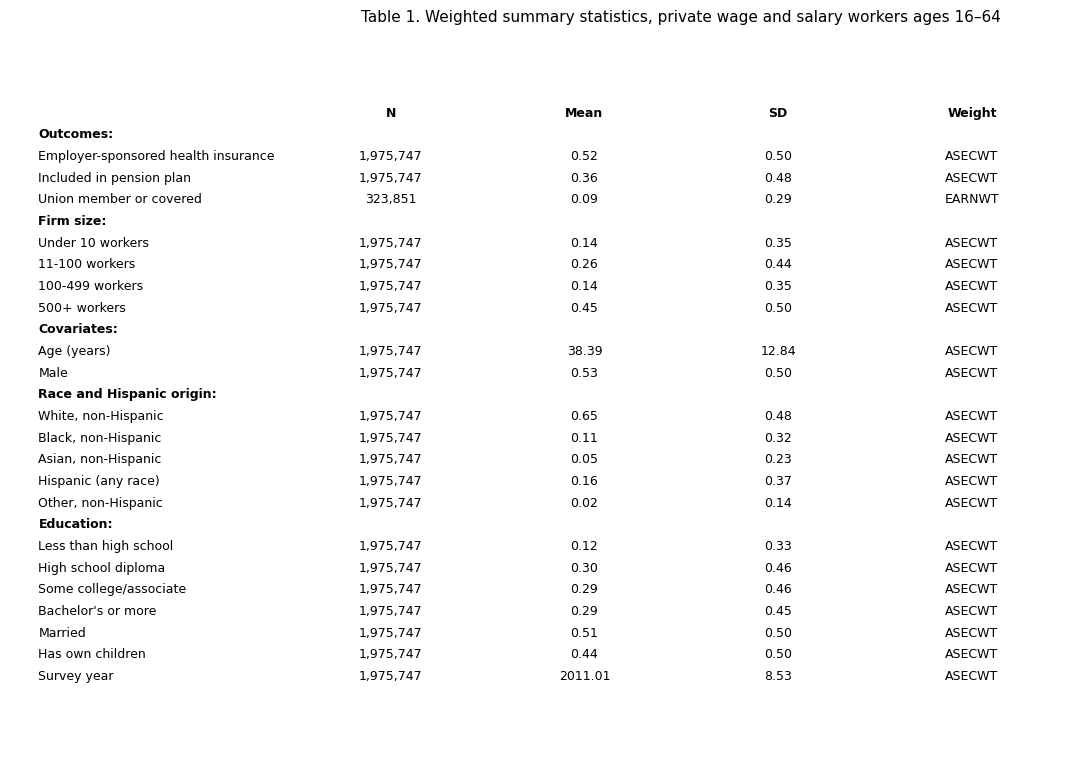

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#DOWNLOAD PREVIOUS TABLE AS AN IMAGE
import matplotlib.pyplot as plt
from google.colab import files

# 1. Turn the numbers into formatted text, the same way the styled table does
out = table1w.copy()
heading_rows = list(headings.values())                       # "Outcomes:", "Firm size:", ...

def fmt(val, col, row):
    if pd.isna(val) or val == "":
        return ""                                            # blank cells in heading rows
    if col == "N":
        return f"{val:,.0f}"
    if col in ["Min", "Max"]:
        return f"{val:,.0f}" if row != "Survey year" else f"{val:.0f}"
    if col in ["Mean", "SD"]:
        return f"{val:.2f}" if row == "Survey year" else f"{val:,.2f}"
    return str(val)                                          # the Weight column

for col in out.columns:
    out[col] = [fmt(v, col, r) for v, r in zip(out[col], out.index)]

# 2. Draw the table
fig, ax = plt.subplots(figsize=(10, 0.32 * len(out) + 1))
ax.axis("off")
tbl = ax.table(cellText=out.values, rowLabels=out.index, colLabels=out.columns,
               loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.3)

# Bold the heading rows and the column names, no borders for a cleaner look
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("white")
    if r == 0:                                               # column names
        cell.set_text_props(weight="bold")
    elif c == -1 and out.index[r - 1] in heading_rows:       # "Outcomes:", etc.
        cell.set_text_props(weight="bold")
    if c == -1:
        cell.set_text_props(ha="left")                       # left-align row labels

ax.set_title("Table 1. Weighted summary statistics, private wage and salary workers ages 16–64",
             fontsize=11, pad=10)

# 3. Save and download
plt.savefig("table1_weighted.png", dpi=200, bbox_inches="tight")
plt.show()
files.download("table1_weighted.png")

In [ ]:
# Where do weighted and unweighted means differ most?
comparison = pd.DataFrame({
    "Unweighted": table1["mean"],
    "Weighted": [wstats(df2, v)["mean"] for v in table1.index],
}, index=table1.index)
comparison["Difference"] = comparison["Weighted"] - comparison["Unweighted"]
comparison.round(3).sort_values("Difference", key=abs, ascending=False)   # biggest differences first

,Unweighted,Weighted,Difference
year,2010.181512,2011.012,0.830469
has_child,0.504803,0.437,-0.067638
age,38.327751,38.390,0.062285
married,0.545465,0.511,-0.034328
hispanic,0.179763,0.163,-0.016645
baplus,0.273005,0.288,0.014527
lths,0.13426,0.121,-0.013488
black,0.099206,0.112,0.013268
large,0.437875,0.450,0.012308
pension,0.367793,0.357,-0.010535


In [ ]:
# A first look at the research question: weighted share with each protection, by firm size
def wmean(d, var):
    wvar = "earnwt" if var in earner_vars else "asecwt"
    d = d.dropna(subset=[var])
    d = d[d[wvar] > 0]
    return np.average(d[var], weights=d[wvar])

by_size = pd.DataFrame({
    var: df2.groupby("firmsize4_label").apply(lambda g, v=var: wmean(g, v))
    for var in ["emp_hins", "pension", "union"]
}).reindex(["Under 10","10-99", "100-499", "500+"]).round(3)
by_size

/tmp/ipykernel_107086/655355576.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  var: df2.groupby("firmsize4_label").apply(lambda g, v=var: wmean(g, v))
/tmp/ipykernel_107086/655355576.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  var: df2.groupby("firmsize4_label").apply(lambda g, v=var: wmean(g, v))
/tmp/ipykernel_107086/655355576.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the g

,emp_hins,pension,union
firmsize4_label,,,
Under 10,0.250,0.118,0.037
11-100,0.430,0.254,0.060
100-499,0.606,0.410,0.099
500+,0.629,0.477,0.119


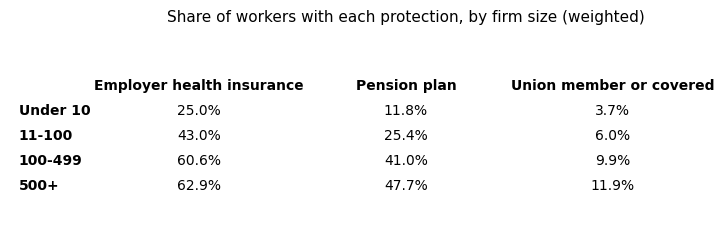

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from google.colab import files

# 1. Readable labels and percentages (easier to read on a slide than 0.523)
out = by_size.rename(columns={"emp_hins": "Employer health insurance",
                              "pension": "Pension plan",
                              "union": "Union member or covered"})
out.index.name = None
out = (out * 100).map(lambda v: f"{v:.1f}%" if pd.notna(v) else "")

# 2. Draw the table
fig, ax = plt.subplots(figsize=(8, 0.4 * len(out) + 1))
ax.axis("off")
tbl = ax.table(cellText=out.values, rowLabels=out.index, colLabels=out.columns,
               loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)

for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("white")
    if r == 0 or c == -1:                                  # column names and firm size labels
        cell.set_text_props(weight="bold")

ax.set_title("Share of workers with each protection, by firm size (weighted)",
             fontsize=11, pad=10)

# 3. Save and download
plt.savefig("protections_by_firm_size.png", dpi=200, bbox_inches="tight")
plt.show()
files.download("protections_by_firm_size.png")

---
## 7. Export

In [ ]:
from google.colab import drive                       # Colab's Google Drive tool
drive.mount("/content/drive")                        # connect Google Drive

df2.to_csv("/content/drive/My Drive/firmsize_clean_data.csv", index=False)   # the clean data, for analysis
table1w.to_csv("/content/drive/My Drive/table1_weighted.csv")                # the table: open in Excel/Sheets
print(df2.shape[0])                                  # rows saved